![Project Logo](images/cardekho_logo.png)

# Project title : Car Dekho Dataset

## Main question
What am I trying to understand?
How the proce is getting impacted by different variables

## Supporting questions
1. Does brand matters
2. How the time of make impact the price
3. Which variable impact the most

In [2]:
# Import the libraries
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)

In [3]:
import scipy.stats as stats
import math
from IPython.display import Markdown

In [4]:
# import the dataset
cardekho_raw = pd.read_csv("data/raw/Car details v3.csv")

In [5]:
cardekho_raw.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [6]:
details_ = pd.DataFrame({'total_entries': [cardekho_raw.size], 'total_rows': [cardekho_raw.shape[0]], 'total_columns': [cardekho_raw.shape[1]]})
display(details_)
col_list = pd.DataFrame({'Variables': [col for col in cardekho_raw.columns], 'dtype': [dtype for dtype in cardekho_raw.dtypes]})
col_list.index = col_list.index + 1
display(col_list)

,total_entries,total_rows,total_columns
0,105664,8128,13


,Variables,dtype
1,name,str
2,year,int64
3,selling_price,int64
4,km_driven,int64
5,fuel,str
6,seller_type,str
7,transmission,str
8,owner,str
9,mileage,str
10,engine,str


In [7]:
cardekho_raw.describe(include='number').round(2)

,year,selling_price,km_driven,seats
count,8128.00,8128.00,8128.00,7907.00
mean,2013.80,638271.81,69819.51,5.42
std,4.04,806253.40,56550.55,0.96
min,1983.00,29999.00,1.00,2.00
25%,2011.00,254999.00,35000.00,5.00
50%,2015.00,450000.00,60000.00,5.00
75%,2017.00,675000.00,98000.00,5.00
max,2020.00,10000000.00,2360457.00,14.00


In [8]:
cardekho_cleaned = cardekho_raw.copy()
cardekho_cleaned['year_bins'] = pd.cut(cardekho_cleaned['year'], bins=[1983,1990, 2000, 2010, 2020], labels=['1980-1990', '1991-2000', '2001-2010', '2011-2020'], include_lowest=True)
cardekho_cleaned['selling_price_bins'] = pd.cut(cardekho_cleaned['selling_price'], bins=[0, 250000, 450000, 675000,10000000], labels=['Low', 'Medium', 'High', 'Very High'], include_lowest=True)
cardekho_cleaned['km_driven_bins'] = pd.cut(cardekho_cleaned['km_driven'], bins=[0, 35000, 60000, 98000, 2360457], labels=['Low', 'Medium', 'High', 'Very High'], include_lowest=True)

In [9]:
col_list_cleaned = pd.DataFrame({'Variables': [col for col in cardekho_cleaned.columns], 'dtype': [dtype for dtype in cardekho_cleaned.dtypes]})
col_list_cleaned.index = col_list_cleaned.index + 1
display(col_list_cleaned)

,Variables,dtype
1,name,str
2,year,int64
3,selling_price,int64
4,km_driven,int64
5,fuel,str
6,seller_type,str
7,transmission,str
8,owner,str
9,mileage,str
10,engine,str


In [10]:
missing_values = pd.DataFrame({'variables':[col for col in cardekho_raw.columns],'missing total':[cardekho_raw[col].isnull().sum() for col in cardekho_raw.columns],'missing %':[round(cardekho_raw[col].isnull().sum()/cardekho_raw.shape[0]*100,2) for col in cardekho_raw.columns]})
display(missing_values[missing_values['missing total']>0].sort_values(by='missing %',ascending=False))

,variables,missing total,missing %
11,torque,222,2.73
8,mileage,221,2.72
9,engine,221,2.72
12,seats,221,2.72
10,max_power,215,2.65


### 

In [11]:
for col in ['year_bins', 'selling_price_bins', 'km_driven_bins', 'fuel', 'seller_type', 'transmission', 'owner']:
    new_table = pd.crosstab(cardekho_cleaned[col], cardekho_cleaned['torque'].isna()).rename(columns={False:'not_missing', True:'missing'})
    new_table['missing_%'] = (new_table['missing'] / new_table.sum(axis=1) * 100).round(2)
    display((pd.DataFrame({"Name of Column": [col]})).style.hide(axis='index'))
    display(new_table)

Name of Column
year_bins


torque,not_missing,missing,missing_%
year_bins,,,
1980-1990,0,1,100.00
1991-2000,52,18,25.71
2001-2010,1271,135,9.60
2011-2020,6583,68,1.02


Name of Column
selling_price_bins


torque,not_missing,missing,missing_%
selling_price_bins,,,
Low,1867,156,7.71
Medium,2113,50,2.31
High,1908,13,0.68
Very High,2018,3,0.15


Name of Column
km_driven_bins


torque,not_missing,missing,missing_%
km_driven_bins,,,
Low,2199,11,0.50
Medium,1859,42,2.21
High,1914,79,3.96
Very High,1934,90,4.45


... (4 outputs left out)

Name of Column
transmission


torque,not_missing,missing,missing_%
transmission,,,
Automatic,1041,9,0.86
Manual,6865,213,3.01


Name of Column
owner


torque,not_missing,missing,missing_%
owner,,,
First Owner,5215,74,1.40
Fourth & Above Owner,160,14,8.05
Second Owner,2016,89,4.23
Test Drive Car,5,0,0.00
Third Owner,510,45,8.11


non of missing values can be removed as max of missing values are from:
1. old vehicles that are from 1980-2000
2. Third, fourth & above owners
3. low mileage
we will keep them while doing uni, bi, multi or corealtion [no na]

In [12]:
cardekho_cleaned['Brand'] = cardekho_cleaned['name'].str.split(n=1).str[0]

In [13]:
cardekho_cleaned.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,year_bins,selling_price_bins,km_driven_bins,Brand
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,2011-2020,Medium,Very High,Maruti
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,2011-2020,Medium,Very High,Skoda
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,2001-2010,Low,Very High,Honda
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,2001-2010,Low,Very High,Hyundai
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,2001-2010,Low,Very High,Maruti


In [14]:
cardekho_cleaned['mileage_read'] = cardekho_cleaned['mileage'].str.split(n=1).str[1]
cardekho_cleaned['mileage_num'] = cardekho_cleaned['mileage'].str.split(n=1).str[0]

In [15]:
cardekho_cleaned['engine_num'] = cardekho_cleaned['engine'].str.split(n=1).str[0]
cardekho_cleaned['engine'].str.split(n=1).str[1].value_counts(dropna=False)

engine
CC     7907
NaN     221
Name: count, dtype: int64

In [16]:
cardekho_cleaned['max_power_num'] = cardekho_cleaned['max_power'].str.split(n=1).str[0]

In [17]:
cardekho_cleaned.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,year_bins,selling_price_bins,km_driven_bins,Brand,mileage_read,mileage_num,engine_num,max_power_num
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0,2011-2020,Medium,Very High,Maruti,kmpl,23.4,1248,74
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0,2011-2020,Medium,Very High,Skoda,kmpl,21.14,1498,103.52
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0,2001-2010,Low,Very High,Honda,kmpl,17.7,1497,78
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0,2001-2010,Low,Very High,Hyundai,kmpl,23.0,1396,90
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0,2001-2010,Low,Very High,Maruti,kmpl,16.1,1298,88.2


In [18]:
cardekho_cleaned.duplicated(keep=False).sum()
cardekho_cleaned = cardekho_cleaned.drop_duplicates()

In [19]:
missing_values_cleaned = pd.DataFrame({'variables':[col for col in cardekho_cleaned.columns],'missing total':[cardekho_cleaned[col].isnull().sum() for col in cardekho_cleaned.columns],'missing %':[round(cardekho_cleaned[col].isnull().sum()/cardekho_cleaned.shape[0]*100,2) for col in cardekho_cleaned.columns]})
display(
    missing_values_cleaned[
        missing_values_cleaned['missing total'] > 0
    ].sort_values('missing %', ascending=False)
)

,variables,missing total,missing %
11,torque,209,3.02
8,mileage,208,3.00
9,engine,208,3.00
12,seats,208,3.00
17,mileage_read,208,3.00
18,mileage_num,208,3.00
19,engine_num,208,3.00
10,max_power,205,2.96
20,max_power_num,205,2.96


In [20]:
for col in ['mileage_num', 'engine_num', 'max_power_num']:
    cardekho_cleaned[col] = pd.to_numeric(
        cardekho_cleaned[col], errors='coerce'
    )

In [21]:
details_1 = pd.DataFrame({'total_entries': [cardekho_cleaned.size], 'total_rows': [cardekho_cleaned.shape[0]], 'total_columns': [cardekho_cleaned.shape[1]]})
display(details_1)
col_list = pd.DataFrame({'Variables': [col for col in cardekho_cleaned.columns], 'dtype': [dtype for dtype in cardekho_cleaned.dtypes]})
col_list.index = col_list.index + 1
display(col_list)

,total_entries,total_rows,total_columns
0,145446,6926,21


,Variables,dtype
1,name,str
2,year,int64
3,selling_price,int64
4,km_driven,int64
5,fuel,str
6,seller_type,str
7,transmission,str
8,owner,str
9,mileage,str
10,engine,str


In [22]:
cardekho_cleaned['seats'].value_counts().sort_values(ascending=True)

seats
14.0       1
2.0        2
10.0      18
6.0       57
9.0       74
4.0      124
8.0      222
7.0      966
5.0     5254
Name: count, dtype: int64

In [23]:
cardekho_cleaned.describe(include='number').round(2)

,year,selling_price,km_driven,seats,mileage_num,engine_num,max_power_num
count,6926.00,6926.00,6926.00,6718.00,6718.00,6718.00,6720.00
mean,2013.42,517270.68,73995.68,5.43,19.47,1430.89,87.73
std,4.08,519766.99,58358.10,0.98,4.05,493.49,31.77
min,1983.00,29999.00,1.00,2.00,0.00,624.00,0.00
25%,2011.00,250000.00,40000.00,5.00,16.80,1197.00,67.10
50%,2014.00,400000.00,70000.00,5.00,19.44,1248.00,81.83
75%,2017.00,633500.00,100000.00,5.00,22.50,1498.00,100.00
max,2020.00,10000000.00,2360457.00,14.00,42.00,3604.00,400.00


In [24]:
cardekho_cleaned.describe(exclude='number').round(2)

,name,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,year_bins,selling_price_bins,km_driven_bins,Brand,mileage_read
count,6926,6926,6926,6926,6926,6718,6718,6721,6717,6926,6926,6926,6926,6718
unique,2058,4,3,2,5,393,121,322,441,4,4,4,32,2
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner,18.9 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,2011-2020,Medium,Very High,Maruti,kmpl
freq,118,3755,6218,6342,4242,210,907,324,472,5501,2000,1897,2165,6631


In [25]:
num_col = cardekho_cleaned.select_dtypes(include='number')
cat_col = cardekho_cleaned.select_dtypes(exclude='number')
cat_col = cat_col[['fuel', 'seller_type', 'transmission', 'owner', 'year_bins', 
                   'selling_price_bins','km_driven_bins', 'Brand', 'mileage_read']]

fuel,count,percentage
Diesel,3755,54.220000
Petrol,3077,44.430000
CNG,56,0.810000
LPG,38,0.550000


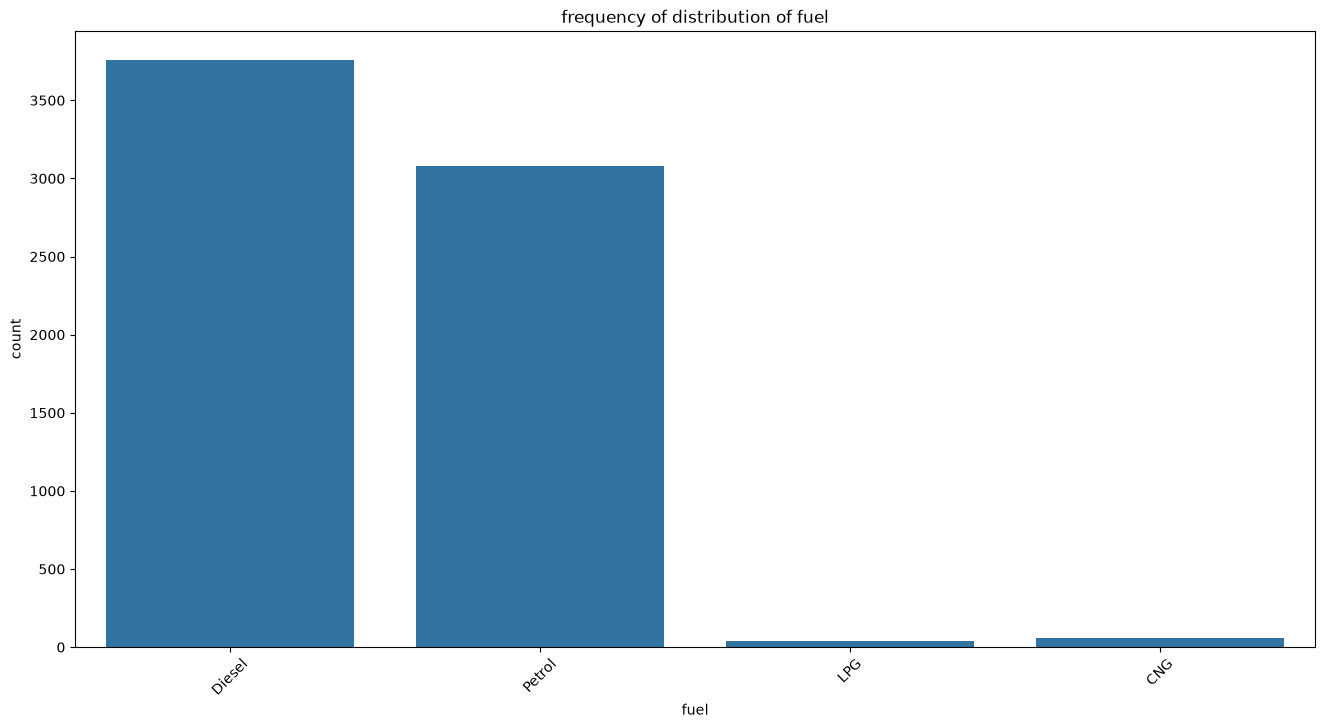

seller_type,count,percentage
Individual,6218,89.780000
Dealer,681,9.830000
Trustmark Dealer,27,0.390000


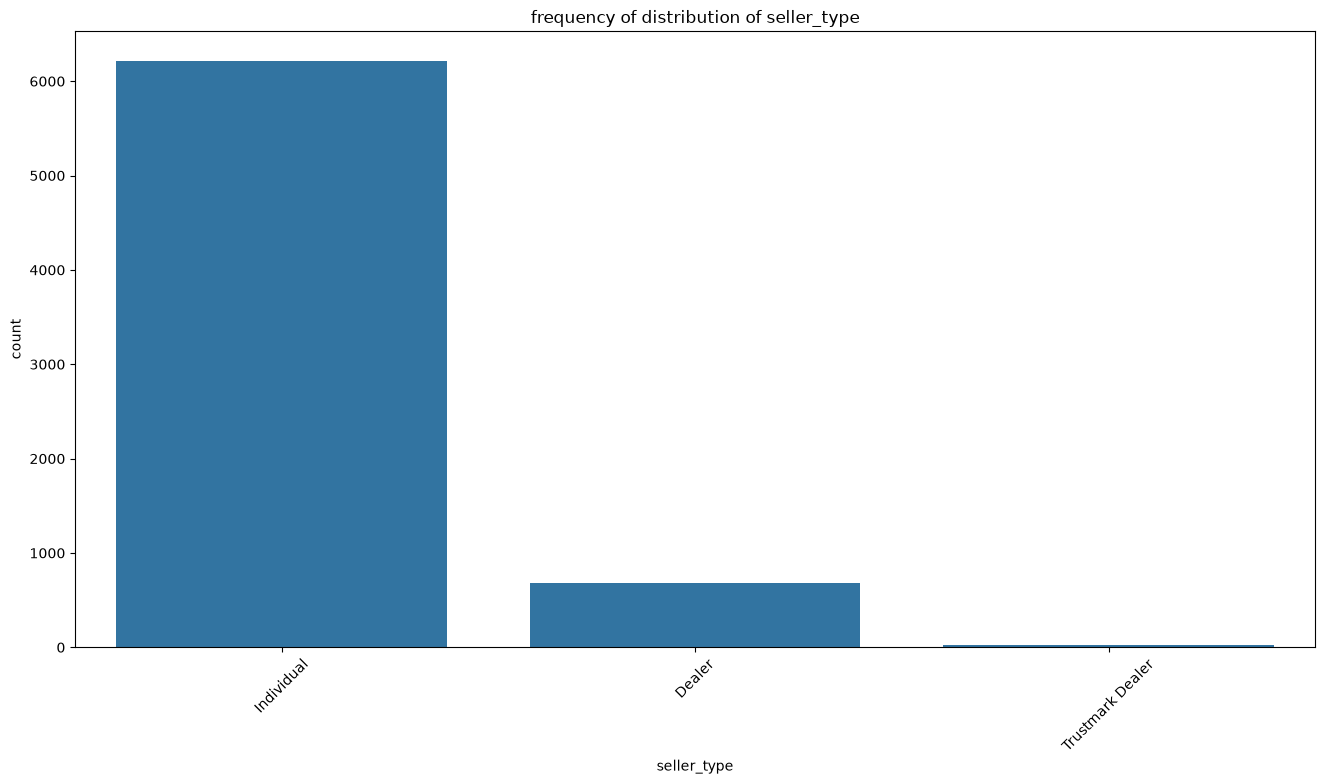

transmission,count,percentage
Manual,6342,91.570000
Automatic,584,8.430000


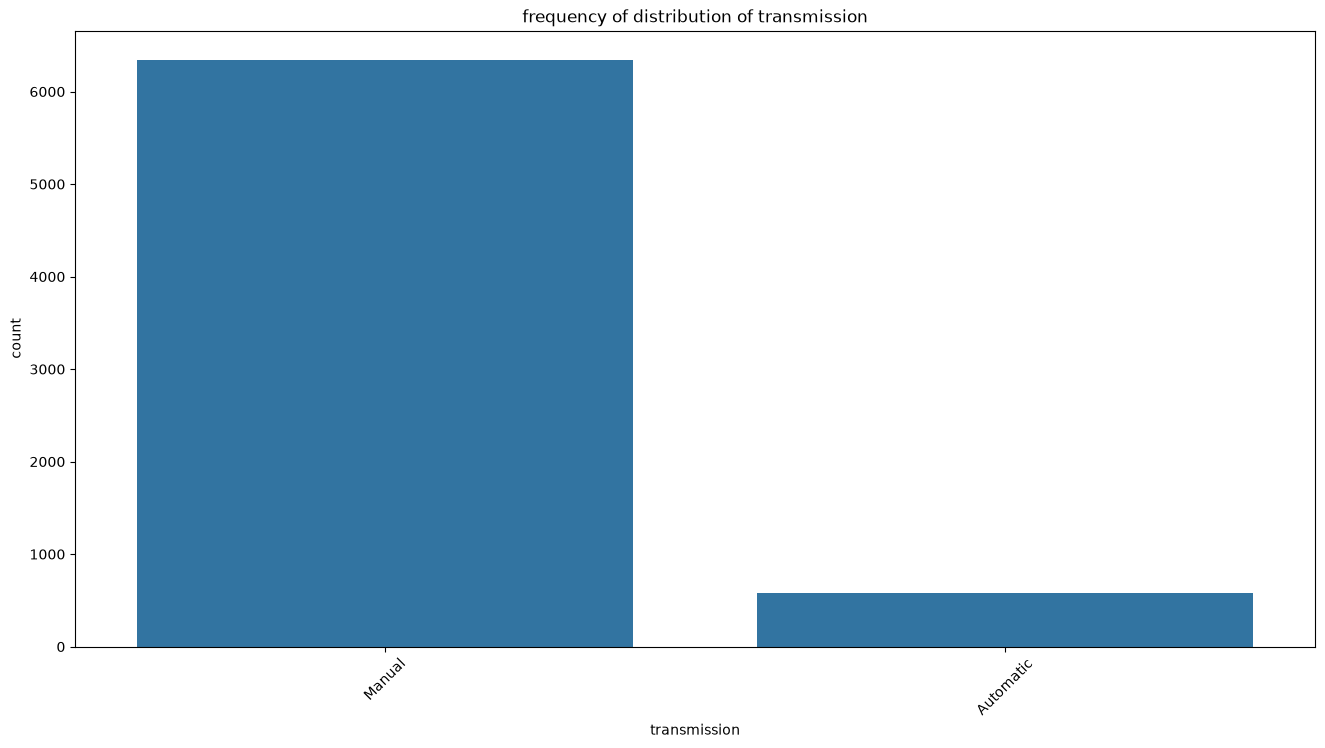

owner,count,percentage
First Owner,4242,61.250000
Second Owner,1974,28.500000
Third Owner,536,7.740000
Fourth & Above Owner,169,2.440000
Test Drive Car,5,0.070000


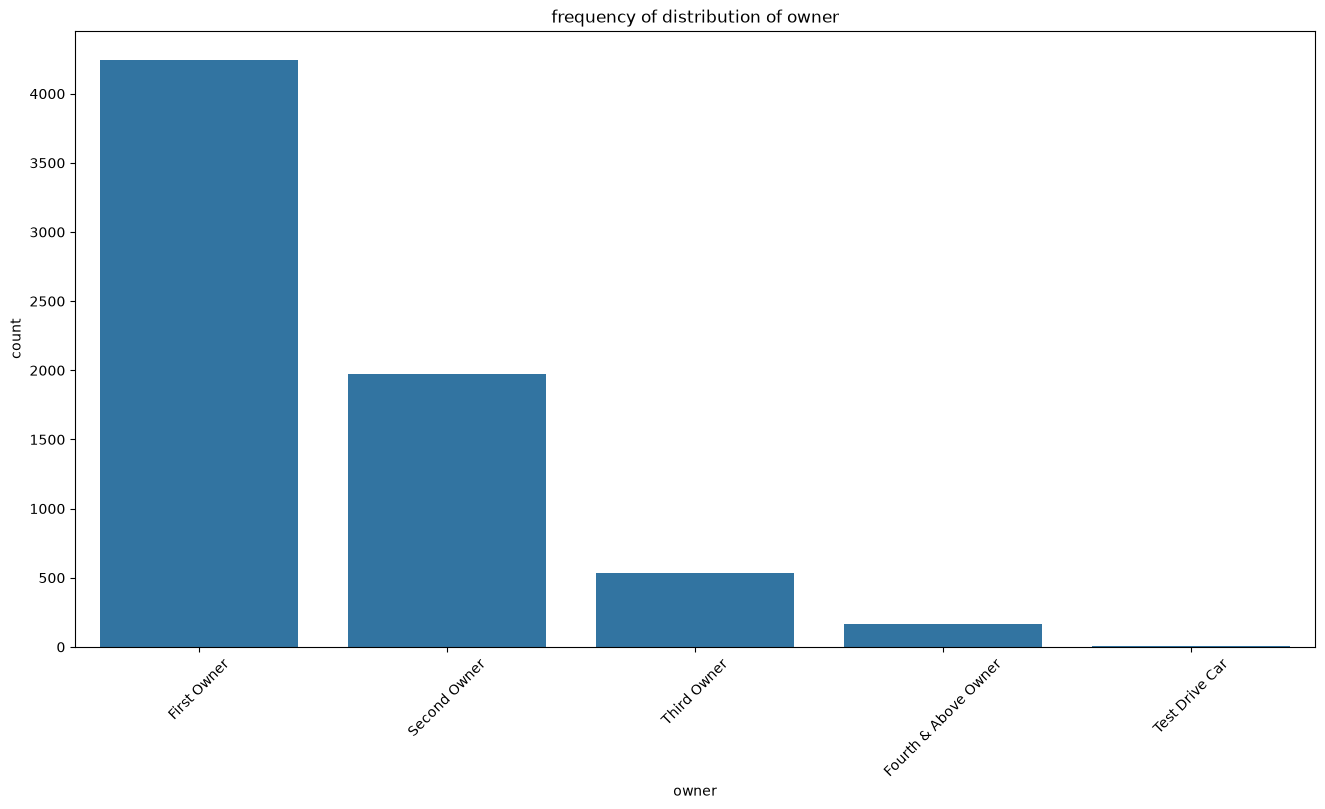

year_bins,count,percentage
2011-2020,5501,79.430000
2001-2010,1357,19.590000
1991-2000,67,0.970000
1980-1990,1,0.010000


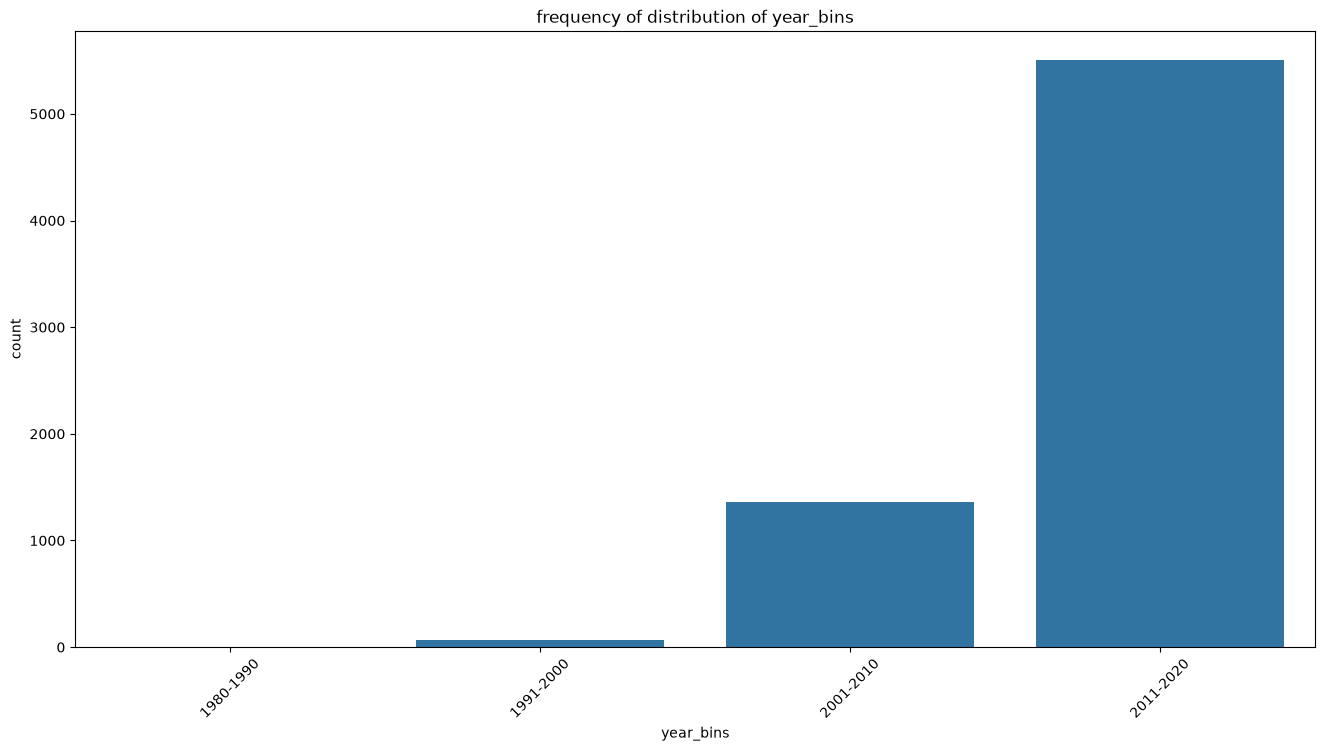

selling_price_bins,count,percentage
Medium,2000,28.880000
Low,1892,27.320000
High,1573,22.710000
Very High,1461,21.090000


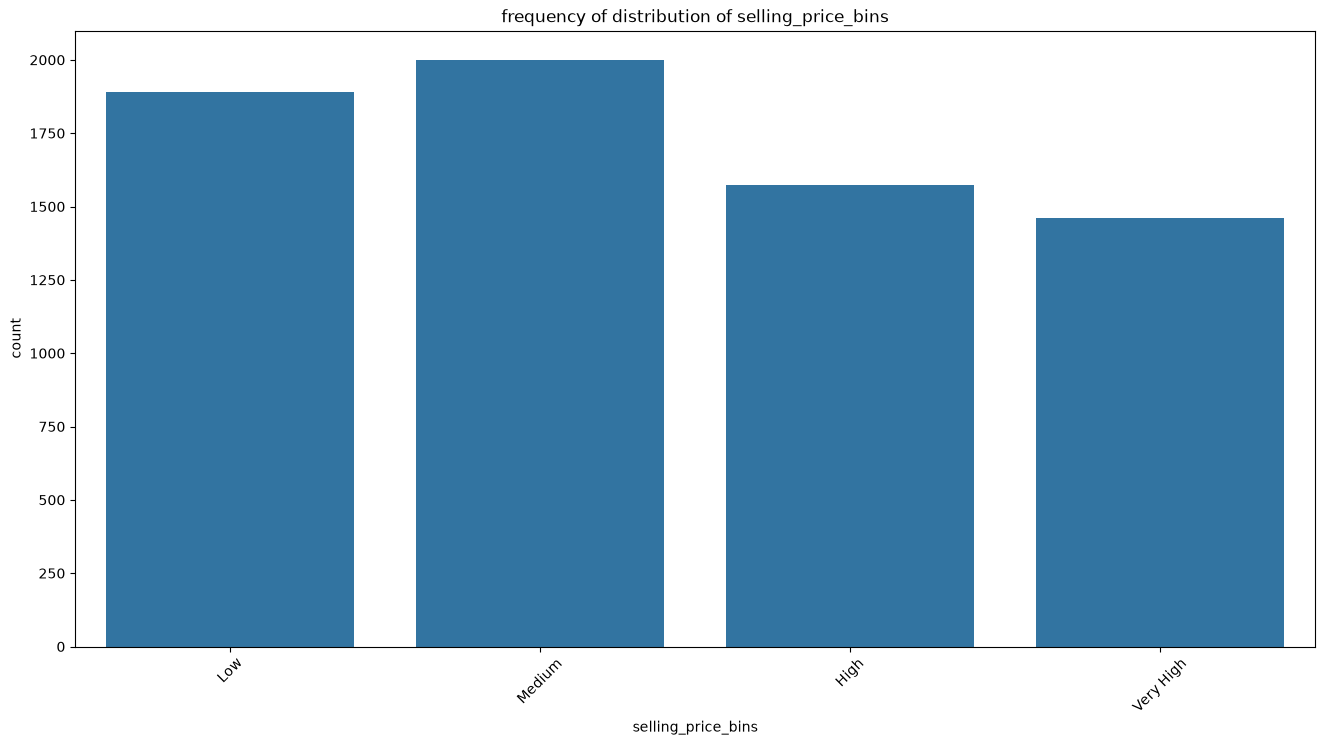

km_driven_bins,count,percentage
Very High,1897,27.390000
High,1790,25.840000
Low,1649,23.810000
Medium,1590,22.960000


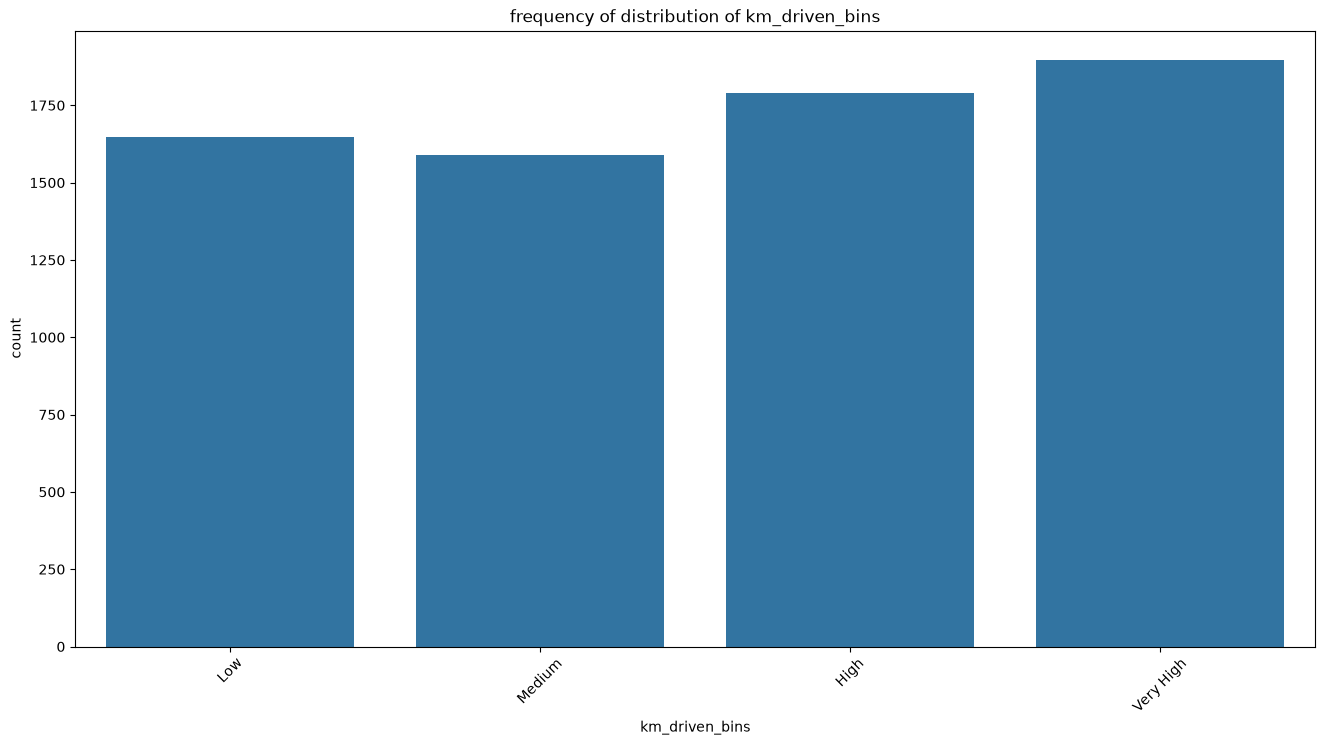

Brand,count,percentage
Maruti,2165,31.260000
Hyundai,1267,18.290000
Mahindra,723,10.440000
Tata,647,9.340000
Honda,362,5.230000
Ford,361,5.210000
Toyota,357,5.150000
Chevrolet,216,3.120000
Renault,206,2.970000
Volkswagen,174,2.510000


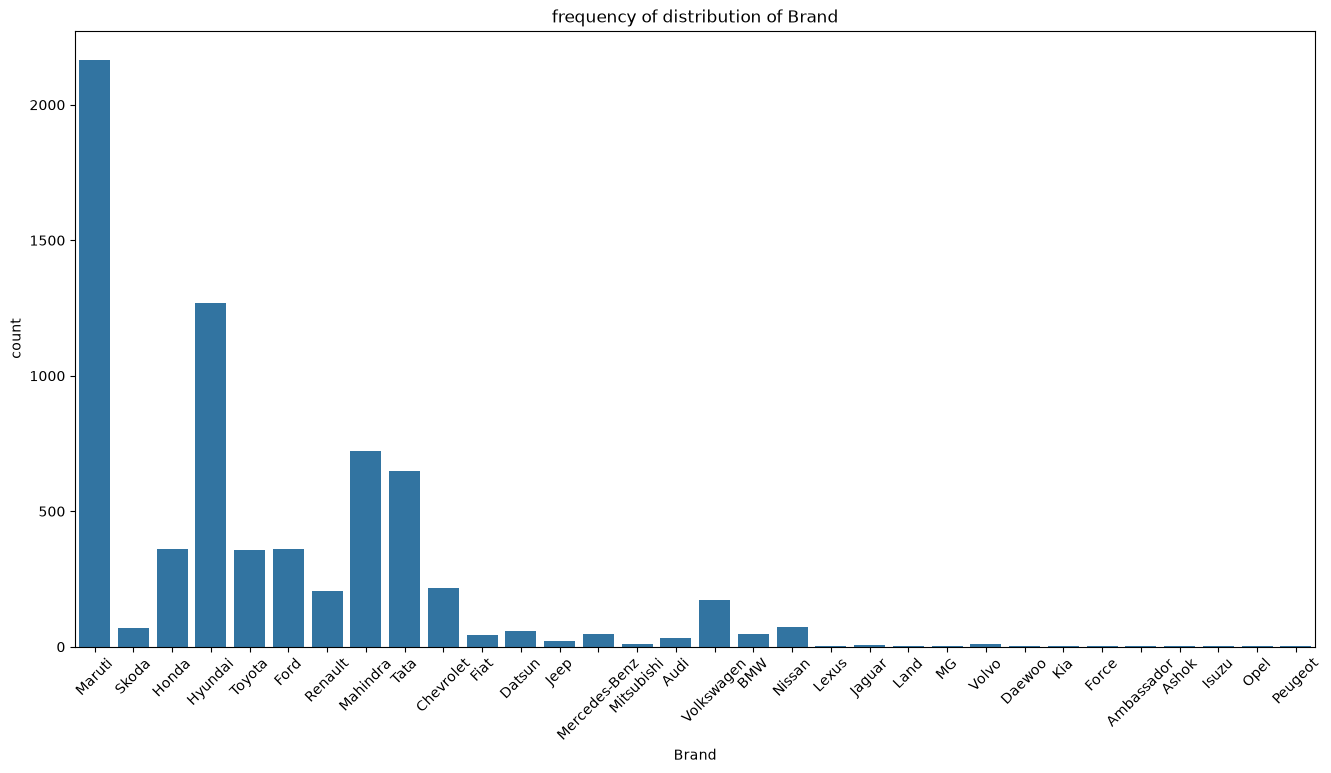

mileage_read,count,percentage
kmpl,6631,95.740000
nan,208,3.000000
km/kg,87,1.260000


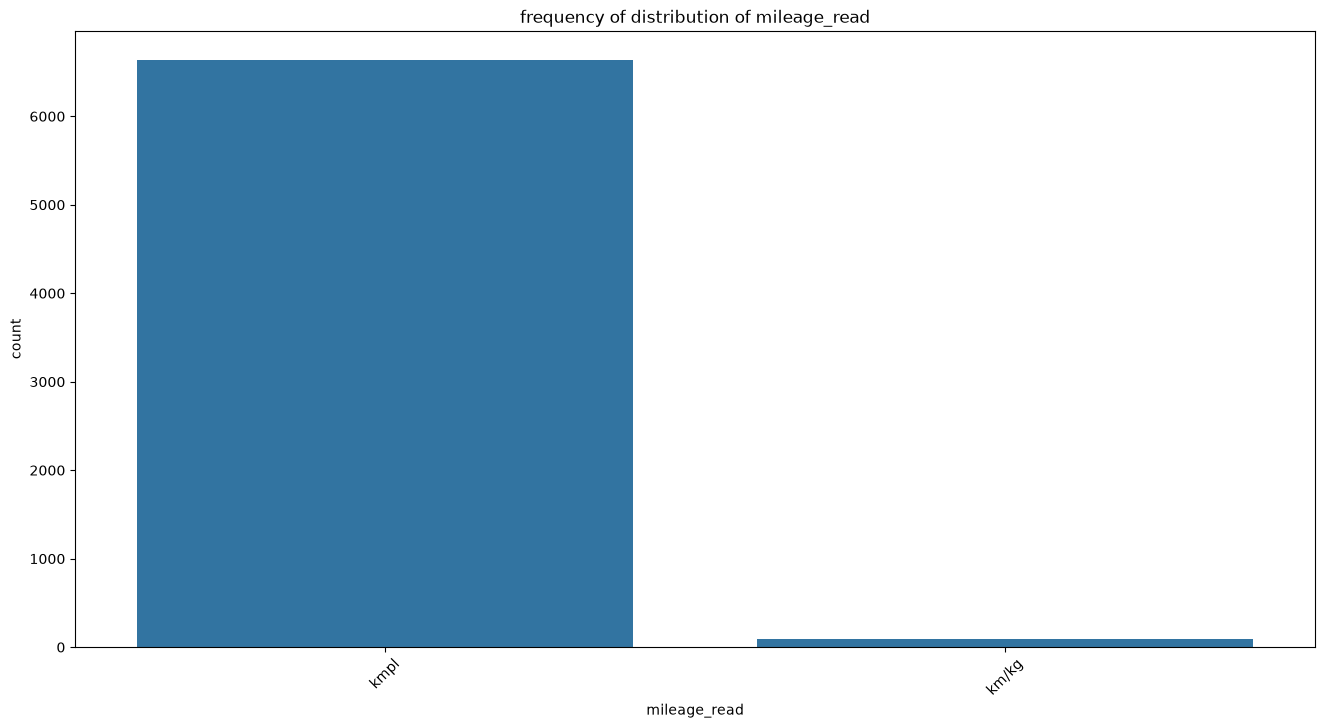

In [26]:
# category coloumns catplot
for col in cat_col.columns:
    plt.figure(figsize=(16,8))
    sns.countplot(data=cardekho_cleaned,x=col)
    new_table_ = (cardekho_cleaned[col].value_counts(dropna=False).reset_index(name='count'))
    new_table_['percentage'] = (new_table_['count'] / len(cardekho_cleaned) * 100).round(2)
    display(new_table_.style.hide(axis='index'))
    plt.xticks(rotation=45)
    plt.xlabel(col)
    plt.ylabel('count')
    plt.title(f"frequency of distribution of {col}")
    plt.show()

In [27]:

display(num_col.dtypes)

year               int64
selling_price      int64
km_driven          int64
seats            float64
mileage_num      float64
engine_num       float64
max_power_num    float64
dtype: object

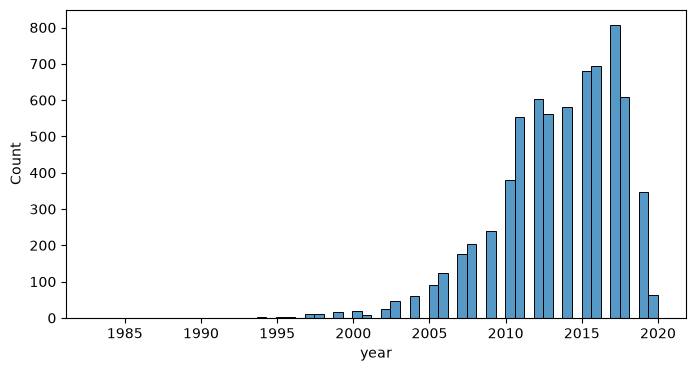

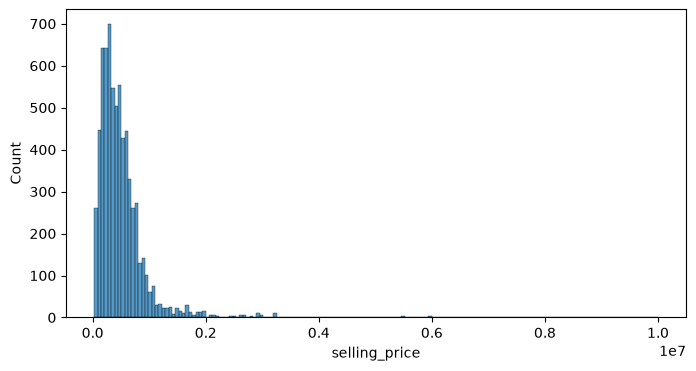

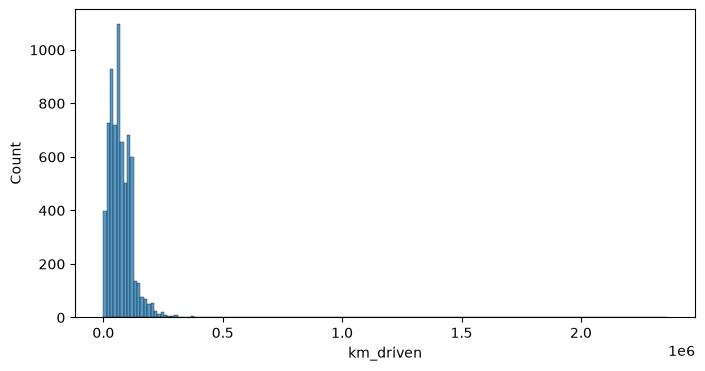

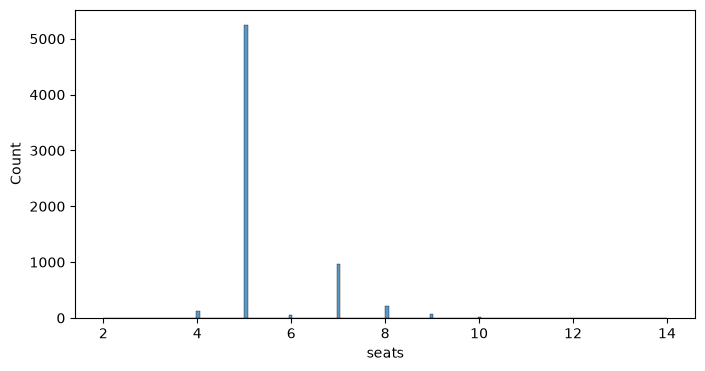

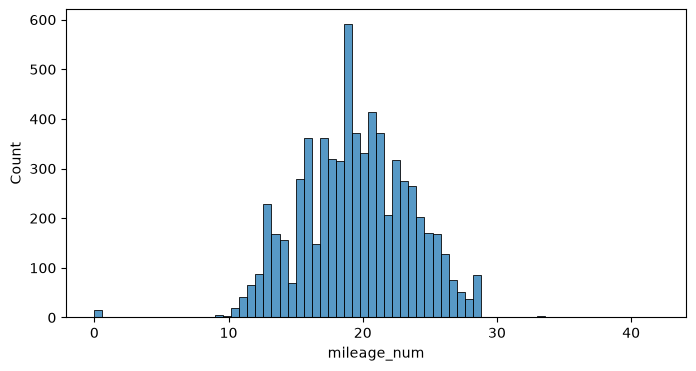

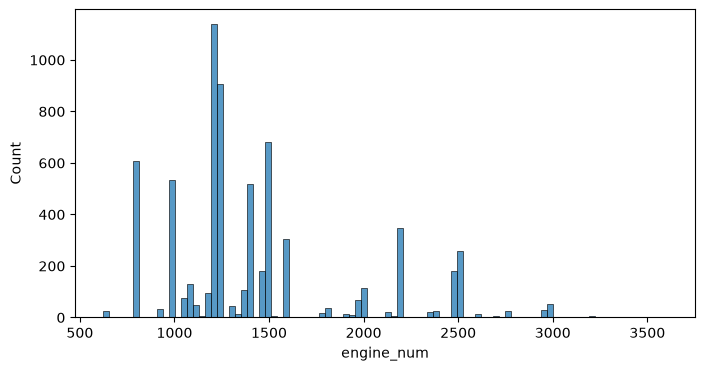

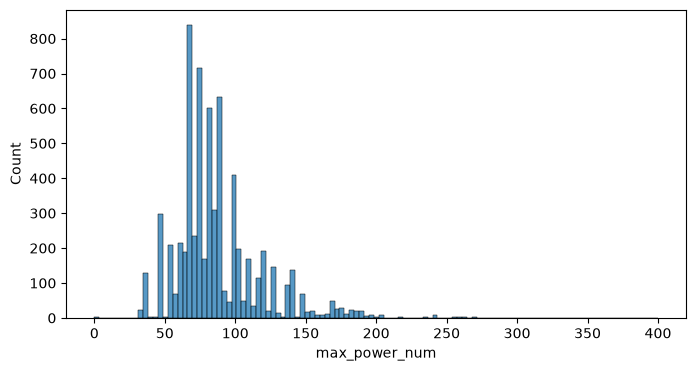

In [29]:
# numerical coloumns analysis
for col in num_col.columns:
    plt.figure(figsize=(8,4))
    sns.histplot(data=cardekho_cleaned,x=col,)
    plt.show()
